In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

In [2]:
DATA_PATH = Path('../src/clean_data.csv')
FS = 360

In [3]:
df = pd.read_csv(DATA_PATH, index_col=0)

signal_columns = sorted(
    [c for c in df.columns if c.startswith('x_')],
    key=lambda c: int(c.split('_')[1])
)

print(f'Liczba uderzeń: {len(df):,}')
print(f'Liczba rekordów: {df["record_id"].nunique()}')
print(f'Liczba próbek w segmencie: {len(signal_columns)}')
print(f'Czas segmentu: {len(signal_columns) / FS} s')
print(f'Zakres record_id: {df["record_id"].min()}-{df["record_id"].max()}')

df.head()

Liczba uderzeń: 93,506
Liczba rekordów: 46
Liczba próbek w segmencie: 180
Czas segmentu: 0.500 s
Zakres record_id: 100-234


,record_id,r_peak,annotation_sample,type,dist_from_annotation,x_0,x_1,x_2,x_3,x_4,...,x_171,x_172,x_173,x_174,x_175,x_176,x_177,x_178,x_179,anomaly
0,100,370,370.0,N,0.0,-0.280,-0.295,-0.305,-0.315,-0.305,...,-0.455,-0.450,-0.435,-0.445,-0.450,-0.455,-0.470,-0.460,-0.455,0
1,100,663,662.0,N,1.0,-0.335,-0.330,-0.335,-0.345,-0.345,...,-0.435,-0.430,-0.435,-0.420,-0.420,-0.420,-0.420,-0.425,-0.425,0
2,100,947,946.0,N,1.0,-0.345,-0.345,-0.345,-0.340,-0.310,...,-0.375,-0.365,-0.370,-0.385,-0.395,-0.385,-0.385,-0.370,-0.365,0
3,100,1231,1231.0,N,0.0,-0.330,-0.320,-0.290,-0.290,-0.300,...,-0.470,-0.455,-0.460,-0.440,-0.435,-0.425,-0.430,-0.445,-0.450,0
4,100,1515,1515.0,N,0.0,-0.320,-0.310,-0.305,-0.305,-0.275,...,-0.445,-0.440,-0.435,-0.430,-0.430,-0.450,-0.445,-0.445,-0.435,0


In [4]:
summary = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'missing_n': df.isna().sum(),
    'missing_pct': 100 * df.isna().mean(),
    'unique_n': df.nunique(dropna=False)
})
summary.loc[['record_id', 'r_peak', 'annotation_sample', 'type', 'dist_from_annotation', 'anomaly']]

,dtype,missing_n,missing_pct,unique_n
record_id,int64,0,0.0,46
r_peak,int64,0,0.0,87367
annotation_sample,float64,0,0.0,87284
type,str,0,0.0,5
dist_from_annotation,float64,0,0.0,49
anomaly,int64,0,0.0,2


In [5]:
duplicate_beats = df.duplicated(subset=['record_id', 'r_peak']).sum()
missing_signal = df[signal_columns].isna().sum().sum()
inf_signal = np.isinf(df[signal_columns].to_numpy(dtype=float)).sum()

print('Duplikaty (record_id, r_peak): ', duplicate_beats)
print('Brakujące wartości w próbkach EKG: ', missing_signal)
print('Wartości nieskończone w próbkach EKG: ', inf_signal)

Duplikaty (record_id, r_peak):  0
Brakujące wartości w próbkach EKG:  0
Wartości nieskończone w próbkach EKG:  0


### Sprawdzenie liczebności klas

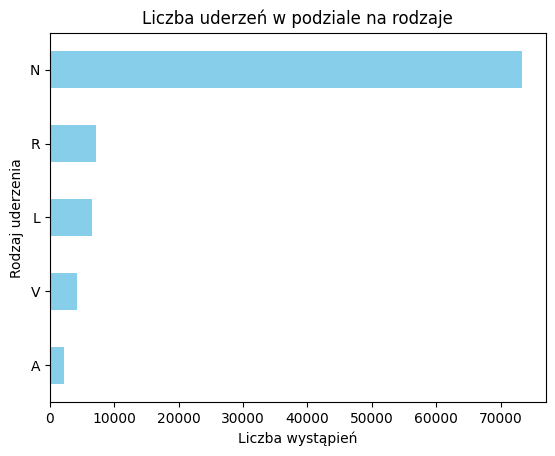

In [6]:
counts = df['type'].value_counts().sort_values()

counts.plot(kind='barh', color='skyblue')
plt.ylabel('Rodzaj uderzenia')
plt.xlabel('Liczba wystąpień')
plt.title('Liczba uderzeń w podziale na rodzaje')
plt.show()

In [7]:
type_distribution = pd.DataFrame({
    'count': counts,
    'pct': round(counts / len(df) * 100, 2)
}).sort_values(
    by='count',
    ascending=False
)
display(type_distribution)

,count,pct
type,,
N,73308,78.40
R,7257,7.76
L,6521,6.97
V,4205,4.50
A,2215,2.37


### Sprawdzenie liczebności anomalia vs. normalny

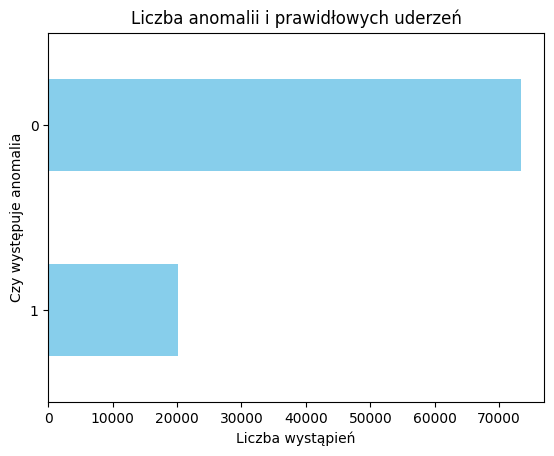

In [8]:
anomalies = df['anomaly'].value_counts().sort_values()

anomalies.plot(kind='barh', color='skyblue')
plt.ylabel('Czy występuje anomalia')
plt.xlabel('Liczba wystąpień')
plt.title('Liczba anomalii i prawidłowych uderzeń')
plt.show()

In [9]:
anomaly_pct = anomalies[1] / (anomalies[0]+anomalies[1]) * 100

print(f'Uderzenia anomalne stanowią {round(anomaly_pct,2)}% wszystkich uderzeń')

Uderzenia anomalne stanowią 21.6% wszystkich uderzeń


#### Sprawdzenie udziału uderzeń anomalnych per record_id

In [10]:
record_id_agg = (
    df.groupby('record_id')
    .agg(
        beats=('anomaly','size'),
        normal=('anomaly', lambda x: (x==0).sum()),
        anomaly=('anomaly', lambda x: (x==1).sum()),
    )
)
record_id_agg['anomaly_pct'] = round(record_id_agg['anomaly'] / record_id_agg['beats'] * 100, 2)

record_id_agg.sort_values('anomaly_pct', ascending=False)

,beats,normal,anomaly,anomaly_pct
record_id,,,,
107,16,0,16,100.00
109,2520,0,2520,100.00
111,2017,0,2017,100.00
207,138,0,138,100.00
124,1541,0,1541,100.00
118,2276,0,2276,100.00
214,2129,0,2129,100.00
232,1776,0,1776,100.00
231,1570,314,1256,80.00


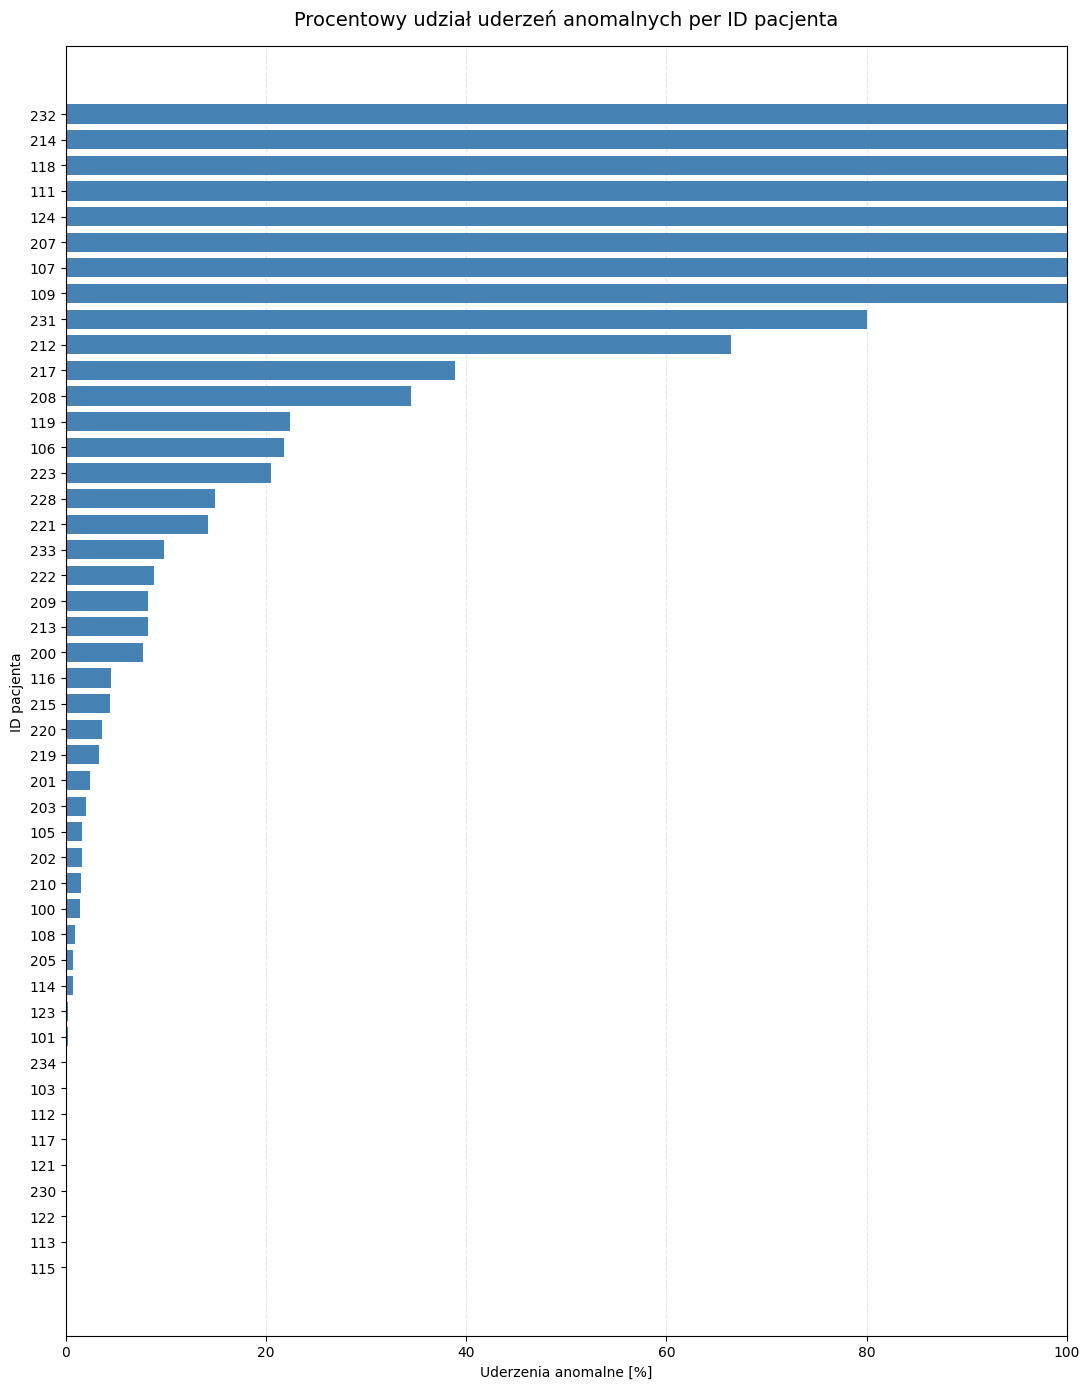

In [11]:
plot_data = record_id_agg.sort_values(
    by='anomaly_pct',
    ascending=True
)

fig, ax = plt.subplots(figsize=(11,14))

ax.barh(
    plot_data.index.astype(str),
    plot_data['anomaly_pct'],
    color='steelblue',
    height=0.75
)

ax.set_title(
    'Procentowy udział uderzeń anomalnych per ID pacjenta',
    fontsize=14,
    pad=15
)
ax.set_xlabel('Uderzenia anomalne [%]')
ax.set_ylabel('ID pacjenta')

ax.set_xlim(0,100)
ax.grid(axis='x',linestyle='--',alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### Sprawdzenie liczby rekordów dla których występują dane typy uderzeń

In [12]:
df['record_id'].nunique()

46

In [13]:
record_id_agg = (
    df.groupby('type')
    .agg(
        beats_count=('type', 'size'),
        record_id_count=('record_id','nunique')
    )
    .sort_values(
        by='beats_count',
        ascending=False
    )
)
record_id_agg

,beats_count,record_id_count
type,,
N,73308,38
R,7257,6
L,6521,4
V,4205,32
A,2215,26


In [14]:
crosstab = pd.crosstab(df['record_id'], df['type'])
crosstab

type,A,L,N,R,V
record_id,,,,,
100,33,0,2237,0,0
101,3,0,1859,0,0
103,2,0,2082,0,0
105,0,0,2457,0,41
106,0,0,1505,0,419
107,0,0,0,0,16
108,3,0,1366,0,9
109,0,2491,0,0,29
111,0,2016,0,0,1


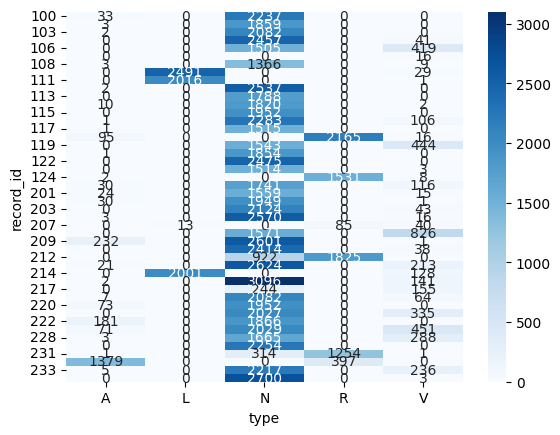

In [15]:
top_ids = crosstab.sum(axis=1).index

ct_top = crosstab.loc[top_ids]

sns.heatmap(
    ct_top,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.show()

### Badanie odległości załamka R od adnotacji

In [16]:
dist = df['dist_from_annotation']

r_peak_stats = pd.DataFrame({
    'samples': {
        'mean': dist.mean(),
        'median': dist.median(),
        'std': dist.std(),
        '90p': dist.quantile(0.90),
        '95p': dist.quantile(0.95),
        '99p': dist.quantile(0.99),
        'max': dist.max()
    }
})

r_peak_stats['ms'] = r_peak_stats['samples'] / FS * 1000

r_peak_stats


,samples,ms
mean,1.070199,2.972774
median,1.000000,2.777778
std,2.316360,6.434333
90p,2.000000,5.555556
95p,2.000000,5.555556
99p,11.000000,30.555556
max,50.000000,138.888889


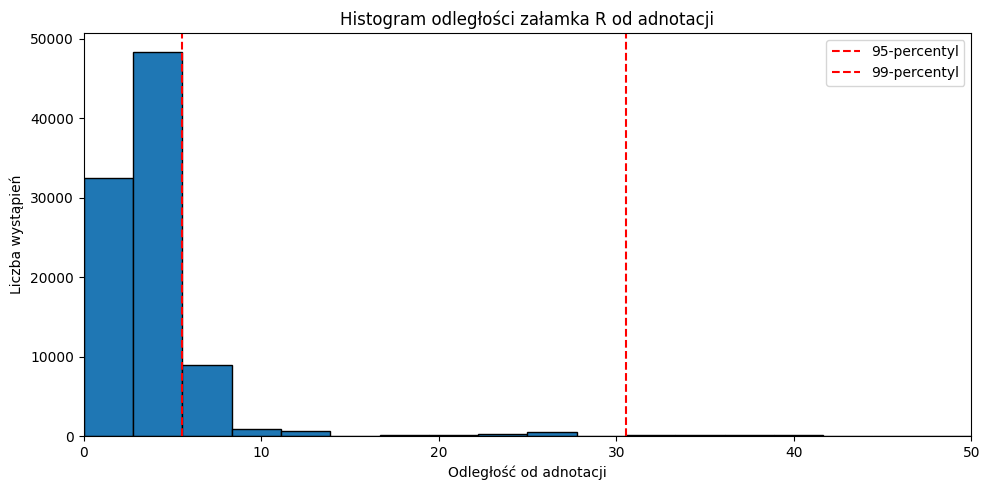

In [21]:
dist = df['dist_from_annotation']

dist_ms = dist / FS * 1000

fig, ax = plt.subplots(figsize=(10,5))

ax.hist(dist_ms, bins=50, edgecolor='black')
ax.set_title("Histogram odległości załamka R od adnotacji")
ax.set_xlabel("Odległość od adnotacji")
ax.set_ylabel("Liczba wystąpień")

ax.axvline(
    dist_ms.quantile(0.95),
    color='red',
    linestyle='--',
    label='95-percentyl'
)
ax.axvline(
    dist_ms.quantile(0.99),
    color='red',
    linestyle='--',
    label='99-percentyl'
)
ax.legend()

ax.set_xlim(0,50)

plt.tight_layout()
plt.show()


In [32]:
peaks_summary = df.groupby('type').agg(
    count=('dist_from_annotation','size'),
    median=('dist_from_annotation', 'median'),
    p95=('dist_from_annotation', lambda x: x.quantile(0.95)),
    max=('dist_from_annotation', 'max')
)

peaks_summary['median_ms'] = peaks_summary['median'] / FS * 1000
peaks_summary['p95_ms'] = peaks_summary['p95'] / FS * 1000
peaks_summary['max_ms'] = peaks_summary['max'] / FS * 1000

peaks_summary

,count,median,p95,max,median_ms,p95_ms,max_ms
type,,,,,,,
A,2215,1.0,2.0,18.0,2.777778,5.555556,50.000000
L,6521,1.0,2.0,47.0,2.777778,5.555556,130.555556
N,73308,1.0,2.0,50.0,2.777778,5.555556,138.888889
R,7257,1.0,2.0,11.0,2.777778,5.555556,30.555556
V,4205,1.0,16.0,50.0,2.777778,44.444444,138.888889


#### Sprawdzenie, dla jakich typów jak często występują duże odległości (>10) adnotacji od załamka R

In [33]:
df['large_error'] = df['dist_from_annotation'] > 10

large_error_pct = (
    df.groupby('type')['large_error']
    .mean() * 100
)

large_error_summary = pd.DataFrame({
    'count': df.groupby('type').size(),
    'large_errors': df.groupby('type')['large_error'].sum(),
    'large_error_pct': round(large_error_pct,2)
}).sort_values(
    by='large_error_pct', ascending=False
)

large_error_summary

C:\Users\weron\AppData\Local\Temp\ipykernel_26244\2744526064.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['large_error'] = df['dist_from_annotation'] > 10


,count,large_errors,large_error_pct
type,,,
V,4205,422,10.04
N,73308,588,0.80
L,6521,40,0.61
A,2215,1,0.05
R,7257,2,0.03


<Axes: ylabel='type'>

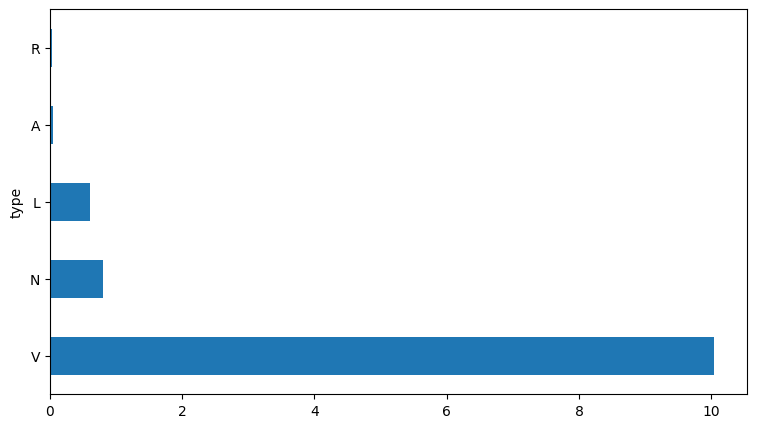

In [34]:
large_error_summary['large_error_pct'].plot(
    kind='barh',
    figsize=(9,5)
)

W klasie V znacznie większa grupa uderzeń z przesunięciem lokalizacji względem adnotacji. V to przedswczesne pobudzenie komorowe, które charakteryzuje się szerszym, nietypowym zespołem QRS. To może utrudniać automatyczne wskazanie położeniua uderzenia, bo algorytm wykorzystany do podziału danych szuka szczytu amplitudy, a adnotacja może wskazywać inny punkt w obrębie QRS.

#### Sprawdzenie udziału 'dużych błędów' per record_id

In [42]:
v_counts = df[df['type'] == 'V'].groupby('record_id').size()

v_large_errors = df[
    (df['type'] == 'V') & 
    (df['dist_from_annotation'] > 10)
].groupby('record_id').size()

v_df = pd.DataFrame({
    'v_count': v_counts,
    'v_large_errors': v_large_errors,
    'large_error_pct': round(v_large_errors / v_counts * 100,2)
}).fillna(0).sort_values(by='large_error_pct', ascending=False)

v_df

,v_count,v_large_errors,large_error_pct
record_id,,,
111,1,1.0,100.00
205,16,15.0,93.75
203,43,33.0,76.74
107,16,10.0,62.50
207,40,20.0,50.00
114,2,1.0,50.00
233,236,96.0,40.68
200,116,30.0,25.86
210,38,9.0,23.68


### Wizualna weryfikacja lokalizacji załamka R

In [51]:
def plot_ecg_segments(beats, before=80, sampling_rate=360):
    signal_cols = [f'x_{i}' for i in range(180)]


    n = len(beats)
    ncols = 3
    nrows = int(np.ceil(n / ncols))


    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(15, 3.5 * nrows),
        squeeze=False,
        sharex=True
    )


    axes = axes.flatten()


    for ax, (_, beat) in zip(axes, beats.iterrows()):
        signal = beat[signal_cols].to_numpy(dtype=float)


        reference_pos = before + (
            beat['annotation_sample'] - beat['r_peak']
        )


        distance_ms = (
            beat['dist_from_annotation'] / sampling_rate * 1000
        )


        ax.plot(
            np.arange(len(signal)),
            signal,
            color='steelblue',
            linewidth=1.5
        )


        ax.axvline(
            before,
            color='red',
            linestyle='--',
            label='Wykryty załamek R'
        )


        ax.axvline(
            reference_pos,
            color='green',
            linestyle=':',
            label='Lokalizacja adnotacji'
        )


        ax.set_title(
            f"Numer rekordu: {beat['record_id']} | Typ {beat['type']}\n"
            f"Odległość: {distance_ms:.1f} ms"
        )


        ax.set_xlabel('Indeks sygnału')
        ax.set_ylabel('Amplituda EKG')
        ax.grid(alpha=0.2)


    for ax in axes[n:]:
        ax.set_visible(False)


    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(
        handles, labels,
        loc='upper center',
        ncol=2,
        bbox_to_anchor=(0.5, 1.02)
    )


    plt.tight_layout()
    plt.show()

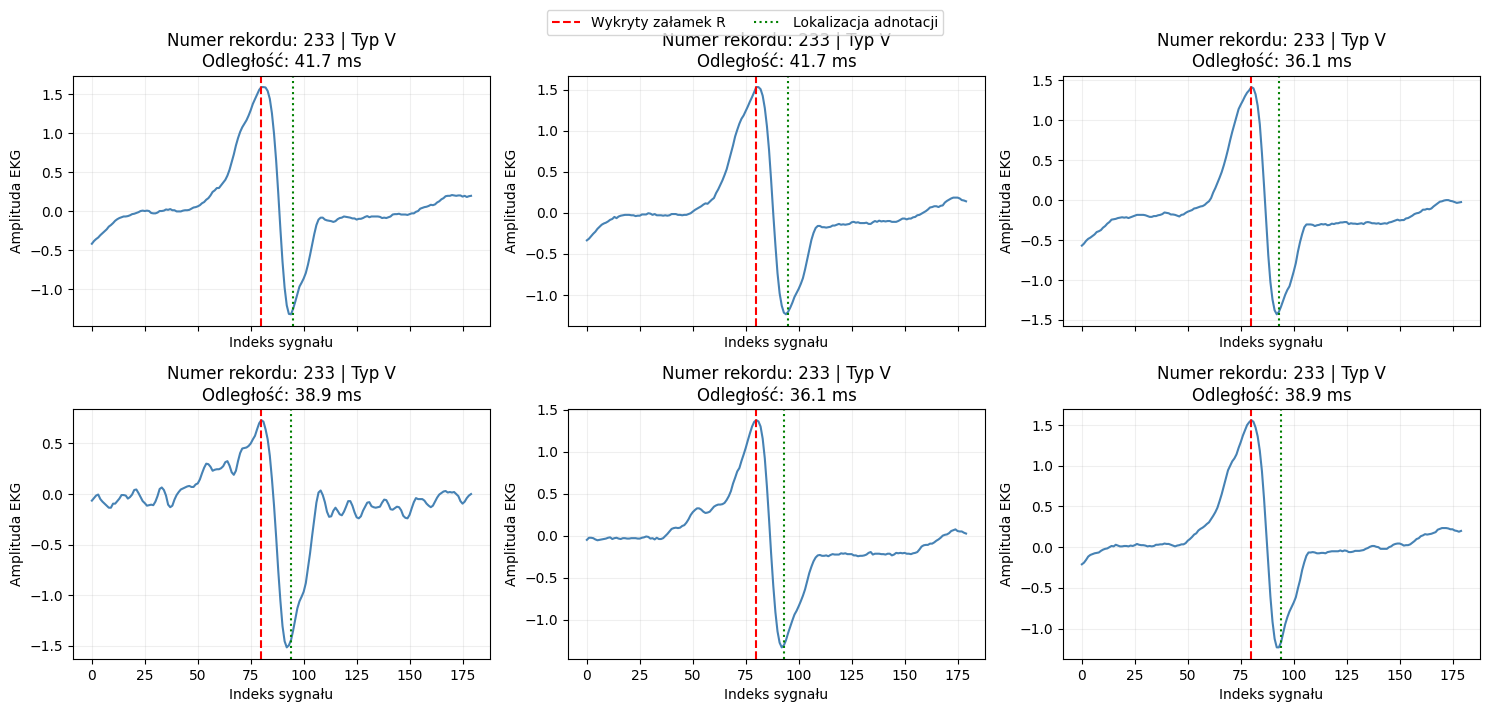

In [52]:
v_233_large = df[
    (df['record_id'] == 233) &
    (df['type'] == 'V') &
    (df['dist_from_annotation'] > 10)
].sample(n=6, random_state=42)


plot_ecg_segments(v_233_large)

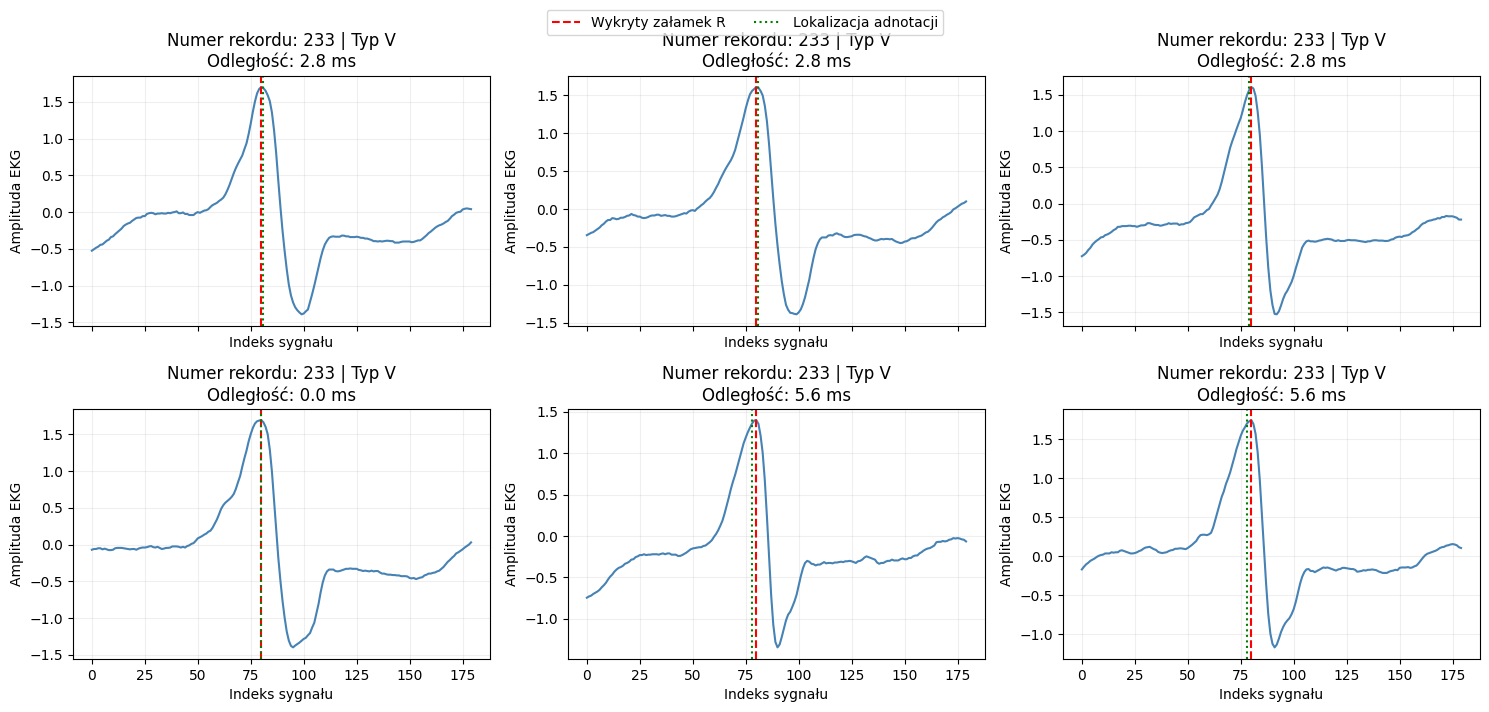

In [53]:
v_233_small = df[
    (df['record_id'] == 233) &
    (df['type'] == 'V') &
    (df['dist_from_annotation'] <= 2)
].sample(n=6, random_state=42)


plot_ecg_segments(v_233_small)

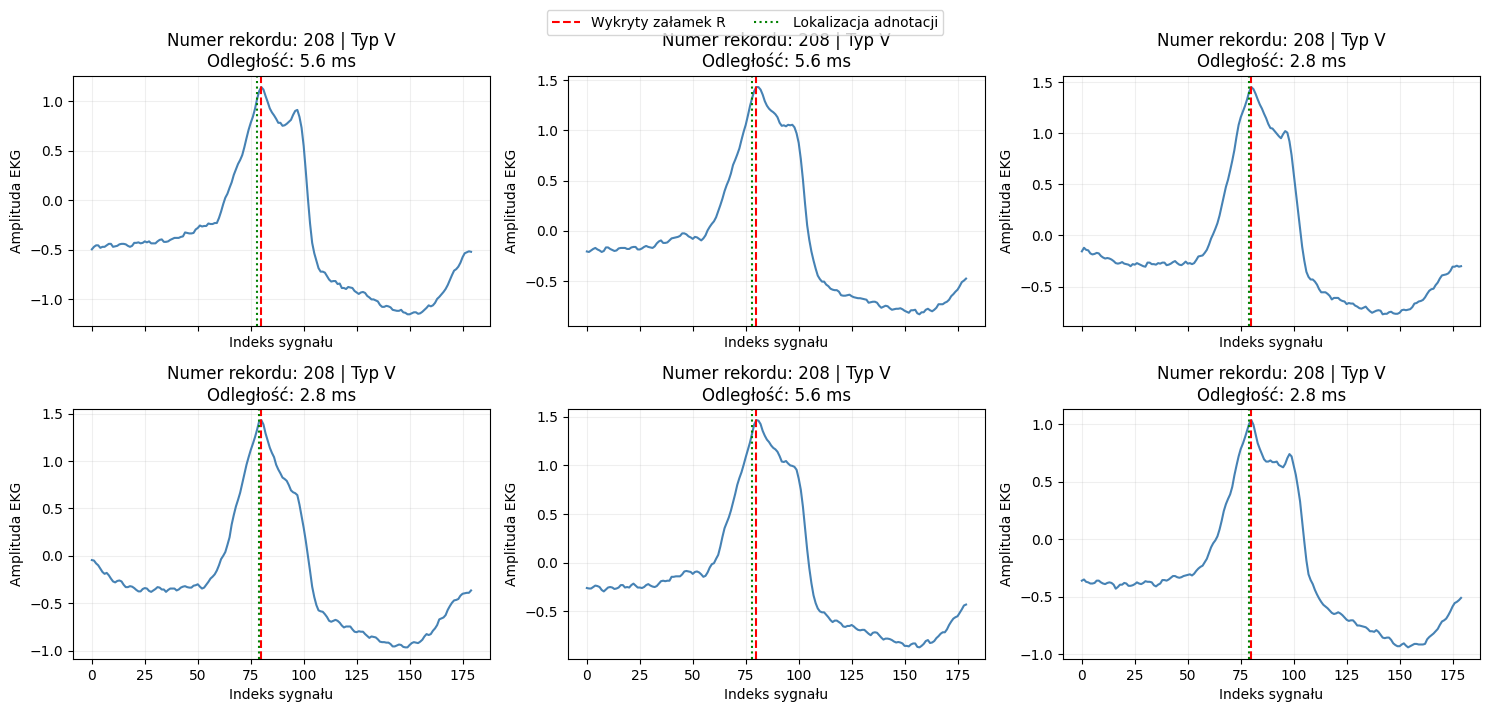

In [54]:
v_208_small = df[
    (df['record_id'] == 208) &
    (df['type'] == 'V') &
    (df['dist_from_annotation'] <= 2)
].sample(n=6, random_state=42)


plot_ecg_segments(v_208_small)